In [ ]:
import os
from pathlib import Path
from getpass import getpass
from google.colab import drive

!nvidia-smi
!apt-get -qq update && apt-get -qq install -y p7zip-full
!pip install -q ultralytics opencv-python-headless onnxruntime onnxslim

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")
ZIP_PASS = getpass("Enter DeepFashion2 zip password: ")

for zname in ["train.zip", "validation.zip", "test.zip"]:
    zpath = DRIVE_ROOT / zname
    assert zpath.exists(), f"Missing {zpath} — check the filename in MyDrive."
    print(f"Found: {zpath} ({zpath.stat().st_size / 1e9:.2f} GB)")

Tue Nov 24 08:00:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

ValueError: mount failed

In [ ]:
from pathlib import Path
from getpass import getpass
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

DRIVE_ROOT = Path("/content/drive/MyDrive")
ZIP_PASS = getpass("Enter DeepFashion2 zip password: ")

for zname in ["train.zip", "validation.zip", "test.zip"]:
    zpath = DRIVE_ROOT / zname
    assert zpath.exists(), f"Missing {zpath} — check the filename in MyDrive."
    print(f"Found: {zpath} ({zpath.stat().st_size / 1e9:.2f} GB)")

Mounted at /content/drive
Enter DeepFashion2 zip password: ··········
Found: /content/drive/MyDrive/train.zip (10.63 GB)
Found: /content/drive/MyDrive/validation.zip (1.82 GB)
Found: /content/drive/MyDrive/test.zip (3.34 GB)


In [ ]:
import json, zipfile, subprocess, shutil
from pathlib import Path

def run_7z(args):
    res = subprocess.run(["7z"] + args, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
    if res.returncode != 0:
        raise RuntimeError(f"7z failed:\n{res.stderr}")

# 1. Count images and JSONs in each archive
for zname in ["train.zip", "validation.zip", "test.zip"]:
    with zipfile.ZipFile(DRIVE_ROOT / zname) as zf:
        names = zf.namelist()
        jpgs = sum(1 for n in names if n.lower().endswith(".jpg"))
        jsons = sum(1 for n in names if n.lower().endswith(".json"))
        print(f"{zname:15s} -> {jpgs:7d} jpgs | {jsons:7d} jsons")

# 2. Extract 1 JSON from test.zip to verify password + check for landmarks
tmp_check = Path("/content/tmp_check")
shutil.rmtree(tmp_check, ignore_errors=True)
tmp_check.mkdir(parents=True)

TEST_HAS_LANDMARKS = False
with zipfile.ZipFile(DRIVE_ROOT / "test.zip") as zf:
    test_jsons = [n for n in zf.namelist() if n.lower().endswith(".json")]

if test_jsons:
    run_7z(["e", f"-p{ZIP_PASS}", f"-o{tmp_check}", str(DRIVE_ROOT / "test.zip"), test_jsons[0], "-y"])
    sample_file = next(tmp_check.glob("*.json"))
    sample_data = json.loads(sample_file.read_text(encoding="utf-8"))
    print("\nPassword verified! Sample test JSON keys:", list(sample_data.keys()))
    for k, v in sample_data.items():
        if k.startswith("item") and isinstance(v, dict):
            print(f"{k} fields:", list(v.keys()))
            if "landmarks" in v and len(v["landmarks"]) > 0:
                TEST_HAS_LANDMARKS = True
            break

shutil.rmtree(tmp_check, ignore_errors=True)
print(f"\nTEST_HAS_LANDMARKS = {TEST_HAS_LANDMARKS}")

train.zip       ->  191961 jpgs |  191961 jsons
validation.zip  ->   32153 jpgs |   32153 jsons
test.zip        ->   62629 jpgs |       3 jsons

Password verified! Sample test JSON keys: ['info', 'licenses', 'images', 'annotations', 'categories']

TEST_HAS_LANDMARKS = False


[train] Extracting JSONs (*0.json, *1.json, *2.json, *3.json) from train.zip...
[train] Selected 2601 clean trousers images.
[train] Extracting 2601 matched images from train.zip...
[train] Ready: 2601 images + YOLO-Pose labels.
[val_all] Extracting JSONs (*.json) from validation.zip...
[val_all] Selected 450 clean trousers images.
[val] Extracting 315 matched images from validation.zip...
[val] Ready: 315 images + YOLO-Pose labels.
[test] Extracting 135 matched images from validation.zip...
[test] Ready: 135 images + YOLO-Pose labels.

Visual check — verify keypoints 0..13 sit cleanly on the trousers:


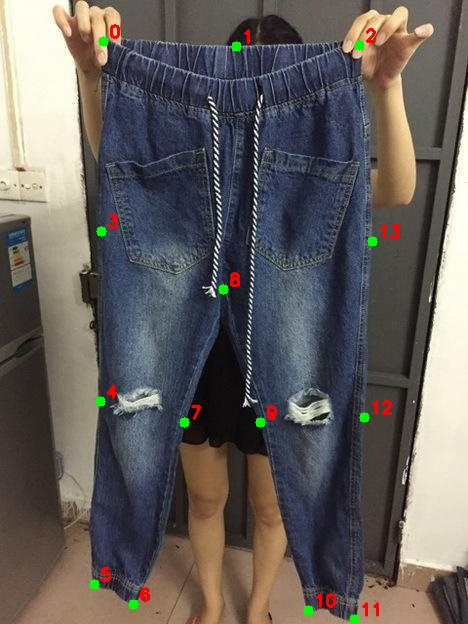

In [ ]:
import json, random, zipfile, shutil
from pathlib import Path
from PIL import Image as PILImage
import cv2
from IPython.display import Image as IPyImage, display

random.seed(42)

OUT_ROOT = Path("/content/datasets/denim_pose")
TMP_ROOT = Path("/content/tmp_extract")
shutil.rmtree(OUT_ROOT, ignore_errors=True)
shutil.rmtree(TMP_ROOT, ignore_errors=True)

TROUSERS_CAT_ID = 8   # DeepFashion2 trousers class
NUM_KPTS = 14         # 14 native trousers landmarks (42 values: x, y, v)

def clamp(v, lo=0.0, hi=1.0):
    return max(lo, min(hi, v))

def collect_clean_trousers(zip_path: Path, tag: str, limit: int, patterns=None):
    anno_dir = TMP_ROOT / f"annos_{tag}"
    anno_dir.mkdir(parents=True, exist_ok=True)
    patterns = patterns or ["*.json"]

    print(f"[{tag}] Extracting JSONs ({', '.join(patterns)}) from {zip_path.name}...")
    run_7z(["e", f"-p{ZIP_PASS}", f"-o{anno_dir}", str(zip_path), *patterns, "-r", "-y"])

    with zipfile.ZipFile(zip_path) as zf:
        jpg_map = {Path(n).stem: n for n in zf.namelist() if n.lower().endswith(".jpg")}

    matched = []
    for jpath in sorted(anno_dir.glob("*.json")):
        stem = jpath.stem
        if stem not in jpg_map:
            continue

        data = json.loads(jpath.read_text(encoding="utf-8"))
        items = []
        for k, item in data.items():
            if not k.startswith("item") or not isinstance(item, dict):
                continue
            if item.get("category_id") != TROUSERS_CAT_ID:
                continue
            if item.get("occlusion", 3) > 1 or item.get("zoom_in", 3) > 1:
                continue
            if item.get("viewpoint", 3) not in (1, 2):
                continue
            lm = item.get("landmarks", [])
            if len(lm) != NUM_KPTS * 3:
                continue
            items.append(item)

        if items:
            matched.append((stem, jpg_map[stem], items))

    shutil.rmtree(anno_dir, ignore_errors=True)
    random.shuffle(matched)
    matched = matched[:limit]
    print(f"[{tag}] Selected {len(matched)} clean trousers images.")
    return matched

def write_split(zip_path: Path, split: str, records: list, save_debug: bool = False):
    img_dir = OUT_ROOT / "images" / split
    lbl_dir = OUT_ROOT / "labels" / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    list_file = TMP_ROOT / f"{split}_imgs.txt"
    list_file.parent.mkdir(parents=True, exist_ok=True)
    list_file.write_text("\n".join(r[1] for r in records) + "\n", encoding="utf-8")

    print(f"[{split}] Extracting {len(records)} matched images from {zip_path.name}...")
    run_7z(["e", f"-p{ZIP_PASS}", f"-o{img_dir}", str(zip_path), f"@{list_file}", "-y"])

    saved = 0
    debug_done = False

    for stem, _, items in records:
        img_path = img_dir / f"{stem}.jpg"
        if not img_path.exists():
            continue

        with PILImage.open(img_path) as im:
            w, h = im.size

        lines = []
        for item in items:
            x1, y1, x2, y2 = item["bounding_box"]
            bw, bh = clamp((x2 - x1) / w), clamp((y2 - y1) / h)
            cx, cy = clamp(((x1 + x2) / 2.0) / w), clamp(((y1 + y2) / 2.0) / h)
            if bw <= 0.01 or bh <= 0.01:
                continue

            lm = item["landmarks"]
            kpts = []
            for i in range(NUM_KPTS):
                kx, ky, kv = lm[3 * i], lm[3 * i + 1], int(lm[3 * i + 2])
                if kv == 0:
                    kpts.append("0.000000 0.000000 0")
                else:
                    kpts.append(f"{clamp(kx / w):.6f} {clamp(ky / h):.6f} {kv}")

            lines.append(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f} " + " ".join(kpts))

            if save_debug and not debug_done:
                vis = cv2.imread(str(img_path))
                for i in range(NUM_KPTS):
                    kx, ky, kv = int(lm[3 * i]), int(lm[3 * i + 1]), int(lm[3 * i + 2])
                    if kv > 0:
                        cv2.circle(vis, (kx, ky), 5, (0, 255, 0), -1)
                        cv2.putText(vis, str(i), (kx + 6, ky - 4),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)
                cv2.imwrite("/content/verify_keypoints.jpg", vis)
                debug_done = True

        if lines:
            (lbl_dir / f"{stem}.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
            saved += 1
        else:
            img_path.unlink(missing_ok=True)

    print(f"[{split}] Ready: {saved} images + YOLO-Pose labels.")

# 1. Extract 3,000 clean trousers from train.zip (uniform 40% JSON scan)
train_recs = collect_clean_trousers(
    DRIVE_ROOT / "train.zip", "train", limit=3000,
    patterns=["*0.json", "*1.json", "*2.json", "*3.json"]
)
write_split(DRIVE_ROOT / "train.zip", "train", train_recs)

# 2. Extract 1,000 clean trousers from validation.zip and split 70% val / 30% test
all_val = collect_clean_trousers(DRIVE_ROOT / "validation.zip", "val_all", limit=1000)
split_idx = int(len(all_val) * 0.7)
write_split(DRIVE_ROOT / "validation.zip", "val", all_val[:split_idx], save_debug=True)
write_split(DRIVE_ROOT / "validation.zip", "test", all_val[split_idx:])

shutil.rmtree(TMP_ROOT, ignore_errors=True)

print("\nVisual check — verify keypoints 0..13 sit cleanly on the trousers:")
display(IPyImage("/content/verify_keypoints.jpg"))

In [ ]:
import shutil

backup_path = shutil.make_archive(
    base_name=str(DRIVE_ROOT / "denim_pose_clean"),
    format="zip",
    root_dir="/content/datasets",
    base_dir="denim_pose",
)
print(f"Saved clean dataset backup to: {backup_path}")

Saved clean dataset backup to: /content/drive/MyDrive/denim_pose_clean.zip


In [ ]:
from pathlib import Path
from ultralytics import YOLO

yaml_content = """path: /content/datasets/denim_pose
train: images/train
val: images/val
test: images/test

kpt_shape: [14, 3]
flip_idx: [2, 1, 0, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3]

names:
  0: trousers
"""
YAML_PATH = Path("/content/denim_pose.yaml")
YAML_PATH.write_text(yaml_content, encoding="utf-8")

model = YOLO("yolo26s-pose.pt")  # Swap to "yolo11s-pose.pt" if you prefer YOLO11

model.train(
    data=str(YAML_PATH),
    epochs=60,
    imgsz=640,
    batch=16,
    fliplr=0.5,         # Safe now because flip_idx is set
    degrees=10.0,       # Slight garment tilt tolerance
    scale=0.3,
    project=str(DRIVE_ROOT / "denim_pp_runs"),
    name="stage1_trousers",
    exist_ok=True,
    save_period=10,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/denim_pose.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f2bb01e99b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [ ]:
import numpy as np
from pathlib import Path
from ultralytics import YOLO

BEST_PT = Path("/content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.pt")
best_model = YOLO(str(BEST_PT))

# 1. Official Ultralytics pose mAP on the untouched 135-image test split
metrics = best_model.val(data="/content/denim_pose.yaml", split="test", imgsz=640)
print(f"\nTest Pose mAP50:    {metrics.pose.map50:.4f}")
print(f"Test Pose mAP50-95: {metrics.pose.map:.4f}")

# 2. Euclidean pixel error (normalized to 640px scale)
test_imgs = sorted(Path("/content/datasets/denim_pose/images/test").glob("*.jpg"))
test_lbl_dir = Path("/content/datasets/denim_pose/labels/test")

all_errors = []
per_kpt_errors = {i: [] for i in range(14)}

for img_path in test_imgs:
    lbl_path = test_lbl_dir / f"{img_path.stem}.txt"
    if not lbl_path.exists():
        continue

    res = best_model.predict(str(img_path), imgsz=640, conf=0.4, verbose=False)[0]
    if res.keypoints is None or len(res.keypoints.xyn) == 0:
        continue

    h, w = res.orig_shape
    scale_640 = 640.0 / max(h, w)
    pred_boxes = res.boxes.xywhn.cpu().numpy()
    pred_kpts = res.keypoints.xyn.cpu().numpy()

    for line in lbl_path.read_text().strip().splitlines():
        toks = [float(x) for x in line.split()]
        gt_cx, gt_cy = toks[1], toks[2]
        gt_kpts = np.array(toks[5:]).reshape(14, 3)

        dists = np.hypot(pred_boxes[:, 0] - gt_cx, pred_boxes[:, 1] - gt_cy)
        best_idx = int(np.argmin(dists))
        if dists[best_idx] > 0.25:
            continue

        p_xy = pred_kpts[best_idx] * np.array([w, h])
        for k in range(14):
            gx_n, gy_n, gv = gt_kpts[k]
            if gv == 2:
                err = np.hypot(p_xy[k, 0] - gx_n * w, p_xy[k, 1] - gy_n * h) * scale_640
                all_errors.append(err)
                per_kpt_errors[k].append(err)

print(f"\n--- Spatial Error on Held-Out Test Split (@640px) ---")
print(f"Mean Pixel Error:   {np.mean(all_errors):.2f} px")
print(f"Median Pixel Error: {np.median(all_errors):.2f} px")
print(f"95th Pct Error:     {np.percentile(all_errors, 95):.2f} px")

print("\nPer-Keypoint Mean Error (@640px):")
for k in range(14):
    if per_kpt_errors[k]:
        print(f"  Keypoint {k:2d}: {np.mean(per_kpt_errors[k]):5.2f} px (n={len(per_kpt_errors[k])})")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s-pose summary (fused): 129 layers, 10,171,713 parameters, 0 gradients, 23.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 29.3±23.8 MB/s, size: 49.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/denim_pose/labels/test... 135 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 135/135 362.7it/s 0.4s
val: New cache created: /content/datasets/denim_pose/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.3it/s 7.0s
                   all        135        136      0.985      0.985       0.99      0.801       0.97      0.971       0.97      0.838
Speed: 4.6ms preprocess, 13.5ms inference, 0.0ms loss, 4.7ms postprocess per ima

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26s-pose summary (fused): 129 layers, 10,171,713 parameters, 0 gradients, 23.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 47, 8400) (22.3 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 4.0s, saved as '/content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.onnx' (39.2 MB)

Export complete (4.8s)
Results saved to /content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.onnx
Predict:         yolo predict task=pose model=/content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.onnx imgsz=640 
Validate:        yolo val task=pose model=/content/d

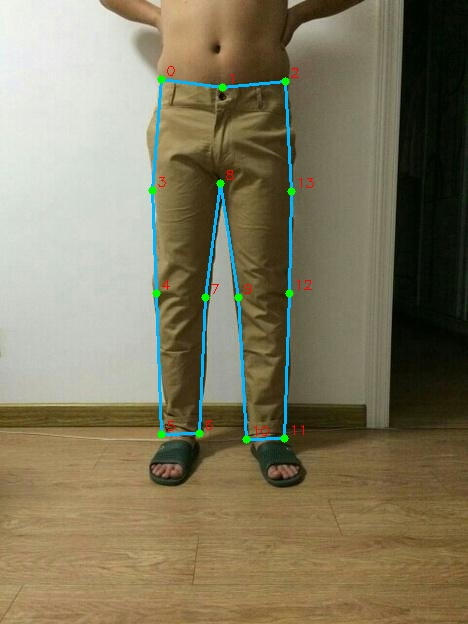

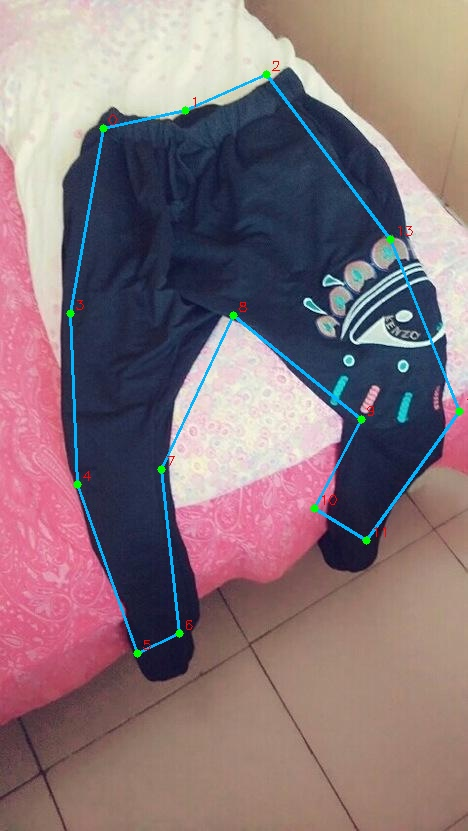

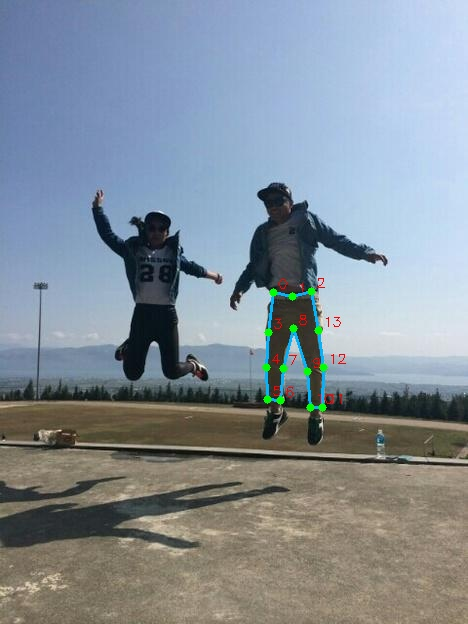

In [ ]:
import time, cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from IPython.display import Image as IPyImage, display

BEST_PT = Path("/content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.pt")
best_model = YOLO(str(BEST_PT))

# 1. Export best.onnx directly into your Google Drive weights folder
onnx_path = best_model.export(format="onnx", imgsz=640, simplify=True)
onnx_model = YOLO(onnx_path, task="pose")
print(f"Saved ONNX to: {onnx_path}")

# 2. Check PyTorch vs ONNX parity
test_imgs = sorted(Path("/content/datasets/denim_pose/images/test").glob("*.jpg"))
sample_img = str(test_imgs[0])
pt_pts = best_model.predict(sample_img, imgsz=640, rect=False, verbose=False)[0].keypoints.xy[0].cpu().numpy()

t0 = time.perf_counter()
onnx_pts = onnx_model.predict(sample_img, imgsz=640, verbose=False)[0].keypoints.xy[0].cpu().numpy()
ms = (time.perf_counter() - t0) * 1000
print(f"Max PT vs ONNX diff: {np.max(np.linalg.norm(pt_pts - onnx_pts, axis=1)):.3f} px | Speed: {ms:.1f} ms")

# 3. Draw 14-keypoint contour on 3 test images
CONTOUR = [(0,1),(1,2),(2,13),(13,12),(12,11),(11,10),(10,9),(9,8),(8,7),(7,6),(6,5),(5,4),(4,3),(3,0)]
out_dir = Path("/content/preview")
out_dir.mkdir(exist_ok=True)

for img_path in test_imgs[:3]:
    res = best_model.predict(str(img_path), imgsz=640, conf=0.5, verbose=False)[0]
    vis = cv2.imread(str(img_path))
    if res.keypoints is not None and len(res.keypoints.xy) > 0:
        pts = res.keypoints.xy[0].cpu().numpy()
        confs = res.keypoints.conf[0].cpu().numpy()
        for a, b in CONTOUR:
            if confs[a] > 0.5 and confs[b] > 0.5:
                cv2.line(vis, tuple(pts[a].astype(int)), tuple(pts[b].astype(int)), (255, 180, 0), 2)
        for i, ((x, y), c) in enumerate(zip(pts, confs)):
            if c > 0.5:
                cv2.circle(vis, (int(x), int(y)), 4, (0, 255, 0), -1)
                cv2.putText(vis, str(i), (int(x) + 5, int(y) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)
    out_file = out_dir / img_path.name
    cv2.imwrite(str(out_file), vis)
    display(IPyImage(str(out_file)))

In [ ]:
!pip install -q ultralytics onnxruntime opencv-python-headless numpy matplotlib yt-dlp

In [ ]:
from pathlib import Path
from google.colab import files

uploaded = files.upload()
src = Path(next(iter(uploaded)))
dst = Path("/content/cargo_jeans.mp4")
if src.resolve() != dst.resolve():
    src.rename(dst)

print(f"Ready: {dst} ({dst.stat().st_size / 1e6:.2f} MB)")

Saving cargo_jeans.mp4 to cargo_jeans.mp4
Ready: /content/cargo_jeans.mp4 (6.34 MB)


In [ ]:
import json, shutil
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ==================== SETTINGS ====================
VIDEO_IN = "/content/cargo_jeans.mp4"
VIDEO_OUT = "/content/annotated_clip.mp4"
WAYPOINTS_JSON = "/content/jaka_waypoints.json"
DRIVE_OUT_DIR = Path("/content/drive/MyDrive/denim_pp_runs/video_test")
DRIVE_OUT_DIR.mkdir(parents=True, exist_ok=True)

START_SEC = 1.8        # Change to your exact start time (seconds)
END_SEC = 4.0          # Change to your exact end time (seconds)

GARMENT_HEIGHT_MM = 1000.0
MANNEQUIN_Y_MM = 650.0
WAIST_Z_MM = 850.0
STANDOFF_MM = 200.0
SPRAY_PASSES = 5
# ==================================================

CONTOUR = [(0,1),(1,2),(2,13),(13,12),(12,11),(11,10),(10,9),(9,8),(8,7),(7,6),(6,5),(5,4),(4,3),(3,0)]

def safety_gate(pts: np.ndarray, confs: np.ndarray, min_conf: float = 0.55) -> tuple[bool, str]:
    core = [0, 1, 2, 3, 4, 7, 8, 9, 12, 13]
    if any(confs[k] < min_conf for k in core):
        return False, "Low conf"
    if not (pts[0, 0] < pts[1, 0] < pts[2, 0]):
        return False, "Waist swap"
    if not (pts[8, 1] > pts[1, 1]):
        return False, "Crotch invalid"
    if not (pts[3, 0] < pts[8, 0] < pts[13, 0]):
        return False, "Hip/crotch invalid"
    if not (pts[4, 0] < pts[7, 0] and pts[9, 0] < pts[12, 0]):
        return False, "Knee swap"
    return True, "PASS"

def bilinear(tl, tr, bl, br, u: float, v: float) -> np.ndarray:
    return (1 - v) * ((1 - u) * tl + u * tr) + v * ((1 - u) * bl + u * br)

def build_curved_3d_zone(tl, tr, bl, br, mm_per_px: float,
                         origin_x_px: float, waist_y_px: float) -> list[dict]:
    waypoints = []
    u_sweep = [0.02, 0.15, 0.32, 0.50, 0.68, 0.85, 0.98]

    for row in range(SPRAY_PASSES):
        v = 0.12 + 0.76 * (row / max(SPRAY_PASSES - 1, 1))
        us = u_sweep if row % 2 == 0 else list(reversed(u_sweep))

        left_edge = (1 - v) * tl + v * bl
        right_edge = (1 - v) * tr + v * br
        leg_radius_mm = max(float(np.linalg.norm(right_edge - left_edge)) * mm_per_px * 0.5, 45.0)
        leg_center_x_mm = ((left_edge[0] + right_edge[0]) * 0.5 - origin_x_px) * mm_per_px

        for u in us:
            pt_2d = bilinear(tl, tr, bl, br, u, v)
            spray_on = 0.14 <= u <= 0.86

            theta = (u - 0.5) * np.deg2rad(70.0)
            nx, ny, nz = float(np.sin(theta)), float(-np.cos(theta)), 0.0

            sx = leg_center_x_mm + leg_radius_mm * np.sin(theta)
            sy = MANNEQUIN_Y_MM - leg_radius_mm * np.cos(theta)
            sz = WAIST_Z_MM - (pt_2d[1] - waist_y_px) * mm_per_px

            px = sx + STANDOFF_MM * nx
            py = sy + STANDOFF_MM * ny
            pz = sz + STANDOFF_MM * nz

            waypoints.append({
                "px_2d": [round(float(pt_2d[0]), 1), round(float(pt_2d[1]), 1)],
                "surface_mm": [round(sx, 2), round(sy, 2), round(sz, 2)],
                "nozzle_mm": [round(px, 2), round(py, 2), round(pz, 2)],
                "normal": [round(nx, 4), round(ny, 4), round(nz, 4)],
                "spray_on": spray_on,
            })
    return waypoints

def build_full_3d_plan(kpts: np.ndarray) -> dict:
    hem_y = np.max(kpts[[5, 6, 10, 11], 1])
    waist_y = float(kpts[1, 1])
    mm_per_px = GARMENT_HEIGHT_MM / max(hem_y - waist_y, 100.0)
    origin_x = float(kpts[1, 0])

    l_tl = 0.25 * kpts[0] + 0.75 * kpts[3]
    l_tr = 0.15 * kpts[1] + 0.85 * kpts[8]
    left_wps = build_curved_3d_zone(l_tl, l_tr, kpts[4], kpts[7], mm_per_px, origin_x, waist_y)

    r_tl = 0.15 * kpts[1] + 0.85 * kpts[8]
    r_tr = 0.25 * kpts[2] + 0.75 * kpts[13]
    right_wps = build_curved_3d_zone(r_tl, r_tr, kpts[9], kpts[12], mm_per_px, origin_x, waist_y)

    return {
        "mm_per_px": round(mm_per_px, 3),
        "standoff_mm": STANDOFF_MM,
        "zones": {"left_thigh": left_wps, "right_thigh": right_wps},
    }

model = YOLO(MODEL_PATH, task="pose")
cap = cv2.VideoCapture(VIDEO_IN)
assert cap.isOpened(), f"Could not open {VIDEO_IN}"

fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
writer = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

cap.set(cv2.CAP_PROP_POS_MSEC, START_SEC * 1000)
passed_kpts_list = []
frame_count = 0

while cap.isOpened():
    cur_sec = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0
    if cur_sec > END_SEC:
        break
    ok, frame = cap.read()
    if not ok:
        break
    frame_count += 1

    res = model.predict(frame, imgsz=640, conf=0.45, verbose=False)[0]
    vis = frame.copy()

    if res.keypoints is not None and len(res.keypoints.xy) > 0:
        pts = res.keypoints.xy[0].cpu().numpy()
        confs = res.keypoints.conf[0].cpu().numpy()
        passed, msg = safety_gate(pts, confs)

        for a, b in CONTOUR:
            if confs[a] > 0.4 and confs[b] > 0.4:
                cv2.line(vis, tuple(pts[a].astype(int)), tuple(pts[b].astype(int)), (255, 180, 0), 2)
        for (x, y), c in zip(pts, confs):
            if c > 0.4:
                cv2.circle(vis, (int(x), int(y)), 4, (0, 255, 0), -1)

        if passed:
            passed_kpts_list.append(pts.copy())
            temp_plan = build_full_3d_plan(pts)
            for wps in temp_plan["zones"].values():
                for i in range(len(wps) - 1):
                    p1 = tuple(int(v) for v in wps[i]["px_2d"])
                    p2 = tuple(int(v) for v in wps[i + 1]["px_2d"])
                    col = (255, 0, 255) if (wps[i]["spray_on"] and wps[i + 1]["spray_on"]) else (0, 255, 255)
                    cv2.line(vis, p1, p2, col, 2)

        color = (0, 230, 0) if passed else (0, 120, 255)
        cv2.putText(vis, f"t={cur_sec:.2f}s | GATE: {msg}", (15, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, color, 2)
    else:
        cv2.putText(vis, f"t={cur_sec:.2f}s | NO GARMENT", (15, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 0, 255), 2)

    writer.write(vis)

cap.release()
writer.release()

print(f"Processed {frame_count} frames ({START_SEC}s–{END_SEC}s)")
print(f"Safety gate passed: {len(passed_kpts_list)}/{frame_count} frames")

if passed_kpts_list:
    locked_kpts = np.median(np.stack(passed_kpts_list, axis=0), axis=0)
    plan_3d = build_full_3d_plan(locked_kpts)

    Path(WAYPOINTS_JSON).write_text(json.dumps(plan_3d, indent=2), encoding="utf-8")
    shutil.copy(WAYPOINTS_JSON, DRIVE_OUT_DIR / "jaka_waypoints.json")
    print(f"Saved 3D waypoints to Drive: {DRIVE_OUT_DIR / 'jaka_waypoints.json'}")

    # Plot 3D spray trajectory inline
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")
    for zone_name, wps in plan_3d["zones"].items():
        surf = np.array([w["surface_mm"] for w in wps])
        noz = np.array([w["nozzle_mm"] for w in wps])
        norms = np.array([w["normal"] for w in wps])

        ax.scatter(surf[:, 0], surf[:, 1], surf[:, 2], c="steelblue", s=16, alpha=0.6,
                   label="Denim surface" if zone_name == "left_thigh" else "")
        for i in range(len(noz) - 1):
            col = "magenta" if (wps[i]["spray_on"] and wps[i + 1]["spray_on"]) else "gold"
            ax.plot(noz[i:i+2, 0], noz[i:i+2, 1], noz[i:i+2, 2], color=col, linewidth=2.2)
        ax.quiver(noz[::2, 0], noz[::2, 1], noz[::2, 2],
                  -norms[::2, 0], -norms[::2, 1], -norms[::2, 2],
                  length=75, color="crimson", alpha=0.75)

    ax.scatter([0], [0], [0], c="black", s=90, marker="^", label="JAKA Base (0,0,0)")
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.set_zlabel("Z (mm)")
    ax.set_title("3D Curved Denim PP Spray Trajectory (Magenta=Spray ON, Red=Nozzle Aim)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No frames passed the safety gate in this window—try adjusting START_SEC / END_SEC.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Loading /content/drive/MyDrive/denim_pp_runs/stage1_trousers/weights/best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnx'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 262ms
Prepared 1 package in 243ms
Installed 1 package in 42ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 227ms
Prepared 1 package in 3.21s
Installed 1 package in 25ms
 + onnxruntime-gpu

TypeError: Object of type float32 is not JSON serializable

Saved 3D waypoints to Drive: /content/drive/MyDrive/denim_pp_runs/video_test/jaka_waypoints.json
Estimated garment scale: 1.1080000400543213 mm/px


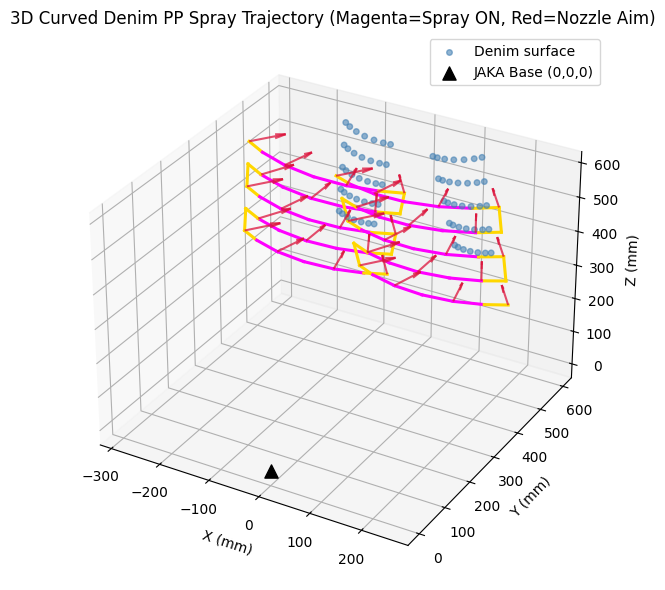

Saved playable video to Drive: /content/drive/MyDrive/denim_pp_runs/video_test/annotated_clip.mp4


In [ ]:
import json, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Video, display

# 1. Serialize numpy scalars cleanly and back up to Google Drive
Path(WAYPOINTS_JSON).write_text(
    json.dumps(plan_3d, indent=2, default=lambda x: x.item()),
    encoding="utf-8",
)
shutil.copy(WAYPOINTS_JSON, DRIVE_OUT_DIR / "jaka_waypoints.json")
print(f"Saved 3D waypoints to Drive: {DRIVE_OUT_DIR / 'jaka_waypoints.json'}")
print(f"Estimated garment scale: {plan_3d['mm_per_px']} mm/px")

# 2. Plot 3D curved thigh trajectory + aiming normals
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

for zone_name, wps in plan_3d["zones"].items():
    surf = np.array([w["surface_mm"] for w in wps])
    noz = np.array([w["nozzle_mm"] for w in wps])
    norms = np.array([w["normal"] for w in wps])

    ax.scatter(surf[:, 0], surf[:, 1], surf[:, 2], c="steelblue", s=16, alpha=0.6,
               label="Denim surface" if zone_name == "left_thigh" else "")
    for i in range(len(noz) - 1):
        col = "magenta" if (wps[i]["spray_on"] and wps[i + 1]["spray_on"]) else "gold"
        ax.plot(noz[i:i+2, 0], noz[i:i+2, 1], noz[i:i+2, 2], color=col, linewidth=2.2)
    ax.quiver(noz[::2, 0], noz[::2, 1], noz[::2, 2],
              -norms[::2, 0], -norms[::2, 1], -norms[::2, 2],
              length=75, color="crimson", alpha=0.75)

ax.scatter([0], [0], [0], c="black", s=90, marker="^", label="JAKA Base (0,0,0)")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_title("3D Curved Denim PP Spray Trajectory (Magenta=Spray ON, Red=Nozzle Aim)")
ax.legend()
plt.tight_layout()
plt.show()

# 3. Convert annotated video to browser-playable H.264, save to Drive, and play inline
!ffmpeg -y -loglevel error -i /content/annotated_clip.mp4 -vcodec libx264 /content/annotated_clip_web.mp4
shutil.copy("/content/annotated_clip_web.mp4", DRIVE_OUT_DIR / "annotated_clip.mp4")
print(f"Saved playable video to Drive: {DRIVE_OUT_DIR / 'annotated_clip.mp4'}")
display(Video("/content/annotated_clip_web.mp4", embed=True, width=380))

In [ ]:
import json, shutil
from pathlib import Path
import numpy as np
from google.colab import files

# Quick check in case Colab disconnected since yesterday
assert "locked_kpts" in globals(), (
    "Colab runtime reset — re-run your video_to_3d_spray cell (Cell 2) once first, then run this cell."
)

MANNEQUIN_Y_MM = 780.0
WAIST_Z_MM = 850.0
STANDOFF_MM = 200.0
GARMENT_HEIGHT_MM = 1000.0
SPRAY_PASSES = 5

def build_curved_3d_zone_clean(tl, tr, bl, br, mm_per_px, origin_x_px, waist_y_px,
                               theta_min_deg, theta_max_deg):
    waypoints = []
    u_sweep = [0.02, 0.15, 0.32, 0.50, 0.68, 0.85, 0.98]

    for row in range(SPRAY_PASSES):
        v = 0.12 + 0.76 * (row / max(SPRAY_PASSES - 1, 1))
        us = u_sweep if row % 2 == 0 else list(reversed(u_sweep))

        left_edge = (1 - v) * tl + v * bl
        right_edge = (1 - v) * tr + v * br
        leg_radius_mm = max(float(np.linalg.norm(right_edge - left_edge)) * mm_per_px * 0.5, 45.0)
        leg_center_x_mm = ((left_edge[0] + right_edge[0]) * 0.5 - origin_x_px) * mm_per_px

        for u in us:
            pt_2d = (1 - v) * ((1 - u) * tl + u * tr) + v * ((1 - u) * bl + u * br)
            spray_on = 0.14 <= u <= 0.86

            theta = np.deg2rad(theta_min_deg + u * (theta_max_deg - theta_min_deg))
            nx, ny, nz = float(np.sin(theta)), float(-np.cos(theta)), 0.0

            sx = leg_center_x_mm + leg_radius_mm * np.sin(theta)
            sy = MANNEQUIN_Y_MM - leg_radius_mm * np.cos(theta)
            sz = WAIST_Z_MM - (pt_2d[1] - waist_y_px) * mm_per_px

            px = sx + STANDOFF_MM * nx
            py = sy + STANDOFF_MM * ny
            pz = sz + STANDOFF_MM * nz

            waypoints.append({
                "px_2d": [round(float(pt_2d[0]), 1), round(float(pt_2d[1]), 1)],
                "surface_mm": [round(sx, 2), round(sy, 2), round(sz, 2)],
                "nozzle_mm": [round(px, 2), round(py, 2), round(pz, 2)],
                "normal": [round(nx, 4), round(ny, 4), round(nz, 4)],
                "spray_on": spray_on,
            })
    return waypoints

hem_y = np.max(locked_kpts[[5, 6, 10, 11], 1])
waist_y = float(locked_kpts[1, 1])
mm_per_px = GARMENT_HEIGHT_MM / max(hem_y - waist_y, 100.0)
origin_x = float(locked_kpts[1, 0])

l_tl = 0.25 * locked_kpts[0] + 0.75 * locked_kpts[3]
l_tr = 0.15 * locked_kpts[1] + 0.85 * locked_kpts[8]
r_tl = 0.15 * locked_kpts[1] + 0.85 * locked_kpts[8]
r_tr = 0.25 * locked_kpts[2] + 0.75 * locked_kpts[13]

clean_plan = {
    "mm_per_px": round(float(mm_per_px), 3),
    "standoff_mm": STANDOFF_MM,
    "zones": {
        "left_thigh": build_curved_3d_zone_clean(l_tl, l_tr, locked_kpts[4], locked_kpts[7],
                                                 mm_per_px, origin_x, waist_y, -32.0, 8.0),
        "right_thigh": build_curved_3d_zone_clean(r_tl, r_tr, locked_kpts[9], locked_kpts[12],
                                                  mm_per_px, origin_x, waist_y, -8.0, 32.0),
    },
}

out_file = Path("/content/jaka_waypoints.json")
out_file.write_text(json.dumps(clean_plan, indent=2, default=lambda x: x.item()), encoding="utf-8")
if "DRIVE_OUT_DIR" in globals():
    shutil.copy(out_file, DRIVE_OUT_DIR / "jaka_waypoints.json")

files.download(str(out_file))
print("Download started for jaka_waypoints.json!")

AssertionError: Colab runtime reset — re-run your video_to_3d_spray cell (Cell 2) once first, then run this cell.

Mounted at /content/drive
Updated clean waypoints saved to: /content/drive/MyDrive/denim_pp_runs/video_test/jaka_waypoints.json


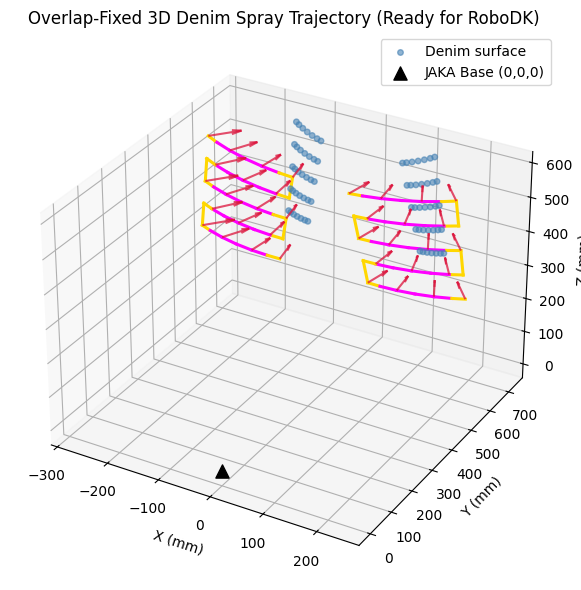

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive, files

drive.mount("/content/drive")

DRIVE_JSON = Path("/content/drive/MyDrive/denim_pp_runs/video_test/jaka_waypoints.json")
assert DRIVE_JSON.exists(), f"File not found at {DRIVE_JSON} — re-run your video inference cell first."

old_plan = json.loads(DRIVE_JSON.read_text(encoding="utf-8"))

MANNEQUIN_Y_MM = 780.0
STANDOFF_MM = 200.0
U_SWEEP = [0.02, 0.15, 0.32, 0.50, 0.68, 0.85, 0.98]

ANGLE_RANGES = {
    "left_thigh": (-32.0, 8.0),    # Asymmetric wrap prevents inner-seam overlap
    "right_thigh": (-8.0, 32.0),
}

new_zones = {}
for zone_name, old_wps in old_plan["zones"].items():
    t_min, t_max = ANGLE_RANGES[zone_name]
    pts_per_row = len(U_SWEEP)
    num_rows = len(old_wps) // pts_per_row
    new_wps = []

    for row in range(num_rows):
        chunk = old_wps[row * pts_per_row : (row + 1) * pts_per_row]
        us = U_SWEEP if row % 2 == 0 else list(reversed(U_SWEEP))

        # Recover exact leg cylinder geometry for this row from saved surface/normal points
        sx_0, sx_mid = chunk[0]["surface_mm"][0], chunk[3]["surface_mm"][0]
        nx_0, nx_mid = chunk[0]["normal"][0], chunk[3]["normal"][0]
        leg_radius_mm = (sx_0 - sx_mid) / (nx_0 - nx_mid)
        leg_center_x_mm = sx_mid - leg_radius_mm * nx_mid

        for wp, u in zip(chunk, us):
            theta = np.deg2rad(t_min + u * (t_max - t_min))
            nx, ny, nz = float(np.sin(theta)), float(-np.cos(theta)), 0.0

            sx = leg_center_x_mm + leg_radius_mm * np.sin(theta)
            sy = MANNEQUIN_Y_MM - leg_radius_mm * np.cos(theta)
            sz = float(wp["surface_mm"][2])

            px = sx + STANDOFF_MM * nx
            py = sy + STANDOFF_MM * ny
            pz = sz + STANDOFF_MM * nz

            new_wps.append({
                "px_2d": wp["px_2d"],
                "surface_mm": [round(sx, 2), round(sy, 2), round(sz, 2)],
                "nozzle_mm": [round(px, 2), round(py, 2), round(pz, 2)],
                "normal": [round(nx, 4), round(ny, 4), round(nz, 4)],
                "spray_on": wp["spray_on"],
            })

    new_zones[zone_name] = new_wps

clean_plan = {
    "mm_per_px": old_plan["mm_per_px"],
    "standoff_mm": STANDOFF_MM,
    "zones": new_zones,
}

# Save locally + update Google Drive copy
out_file = Path("/content/jaka_waypoints.json")
out_file.write_text(json.dumps(clean_plan, indent=2), encoding="utf-8")
shutil.copy(out_file, DRIVE_JSON)
print(f"Updated clean waypoints saved to: {DRIVE_JSON}")

# Quick 3D verification plot (confirm center yellow loops no longer cross)
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
for zone_name, wps in clean_plan["zones"].items():
    surf = np.array([w["surface_mm"] for w in wps])
    noz = np.array([w["nozzle_mm"] for w in wps])
    norms = np.array([w["normal"] for w in wps])

    ax.scatter(surf[:, 0], surf[:, 1], surf[:, 2], c="steelblue", s=16, alpha=0.6,
               label="Denim surface" if zone_name == "left_thigh" else "")
    for i in range(len(noz) - 1):
        col = "magenta" if (wps[i]["spray_on"] and wps[i + 1]["spray_on"]) else "gold"
        ax.plot(noz[i:i+2, 0], noz[i:i+2, 1], noz[i:i+2, 2], color=col, linewidth=2.2)
    ax.quiver(noz[::2, 0], noz[::2, 1], noz[::2, 2],
              -norms[::2, 0], -norms[::2, 1], -norms[::2, 2],
              length=75, color="crimson", alpha=0.75)

ax.scatter([0], [0], [0], c="black", s=90, marker="^", label="JAKA Base (0,0,0)")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_title("Overlap-Fixed 3D Denim Spray Trajectory (Ready for RoboDK)")
ax.legend()
plt.tight_layout()
plt.show()

# Trigger automatic download to your PC
files.download(str(out_file))